In [2]:
%pip install -q qiskit qiskit-aer scikit-learn pandas numpy matplotlib scipy

Include Dataset

In [3]:
import requests
import zipfile
import io
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/748/sirtuin6+small+molecules-1.zip"

try:
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        file_list = z.namelist()
        print("Files in ZIP:")
        print(*file_list, sep="\n")

        candidates = [
            f for f in file_list
            if f.lower().endswith((".csv", ".data"))
            and not f.endswith("/")
        ]

        if not candidates:
            raise ValueError("No CSV or DATA file found in the ZIP.")

        # Inspect candidates and choose the actual dataset file.
        data_file = candidates[0]
        print("\nSelected file:", data_file)

        raw = z.read(data_file)

        try:
            df = pd.read_csv(io.BytesIO(raw))
            if df.shape[1] == 1:
                df = pd.read_csv(io.BytesIO(raw), sep=None, engine="python")
        except Exception:
            df = pd.read_csv(io.BytesIO(raw), sep=None, engine="python")

    print("\nDataset loaded successfully!")
    print("Shape:", df.shape)
    display(df.head())
    print("\nColumns:", df.columns.tolist())

except Exception as e:
    print("Error loading dataset:", e)

Files in ZIP:
SIRTUIN6.csv

Selected file: SIRTUIN6.csv

Dataset loaded successfully!
Shape: (100, 7)


,SC-5,SP-6,SHBd,minHaaCH,maxwHBa,FMF,Class
0,0.540936,7.64192,0.162171,0.445270,2.20557,0.467742,High_BFE
1,0.815332,6.59011,0.000000,0.497445,2.00314,0.415385,High_BFE
2,0.734399,6.85522,0.000000,0.507748,1.88590,0.400000,High_BFE
3,0.624557,7.00949,0.450300,0.483648,2.02757,0.500000,High_BFE
4,0.460290,4.92643,0.448998,0.482293,2.06438,0.536585,High_BFE



Columns: ['SC-5', 'SP-6', 'SHBd', 'minHaaCH', 'maxwHBa', 'FMF', 'Class']


In [4]:
df.to_csv("sirt6_dataset.csv", index=False)

In [ ]:

# ============================================================
# ProteinQ: Quantum Machine Learning for SIRT6 Classification
# Custom VQC + Training Improvement Experiments + SVM Baseline
# ============================================================

%pip -q install qiskit scipy scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from scipy.optimize import minimize

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)


In [6]:
# ============================================================
# 1. DATA PREPARATION
# ============================================================

df = df.dropna().copy()

X_clean = df.iloc[:, :-1].astype(float)
y_clean = df.iloc[:, -1]

unique_labels = np.unique(y_clean.to_numpy())

if len(unique_labels) != 2:
    raise ValueError(f"Expected 2 classes, found {unique_labels}")

# Map first class to 0 and second class to 1
y_binary = np.where(y_clean.to_numpy() == unique_labels[0], 0, 1)

print("Dataset:", X_clean.shape)
print("Features:", X_clean.columns.tolist())
print("Target classes:", unique_labels)

# Outer split: test set is reserved for final evaluation
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_clean.to_numpy(),
    y_binary,
    test_size=0.25,
    random_state=SEED,
    stratify=y_binary
)

# Inner split: use validation data to choose model configuration
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Separate scalers prevent information leakage
tuning_scaler = StandardScaler()
X_train_scaled = tuning_scaler.fit_transform(X_train)
X_val_scaled = tuning_scaler.transform(X_val)

final_scaler = StandardScaler()
X_train_final = final_scaler.fit_transform(X_train_full)
X_test_final = final_scaler.transform(X_test)

# Map standardized values to bounded rotation angles
X_train_angles = 2 * np.arctan(X_train_scaled)
X_val_angles = 2 * np.arctan(X_val_scaled)
X_train_final_angles = 2 * np.arctan(X_train_final)
X_test_final_angles = 2 * np.arctan(X_test_final)

N_QUBITS = X_train_angles.shape[1]

print("Training samples for tuning:", len(y_train))
print("Validation samples:", len(y_val))
print("Final training samples:", len(y_train_full))
print("Held-out test samples:", len(y_test))
print("Qubits:", N_QUBITS)


Dataset: (100, 6)
Features: ['SC-5', 'SP-6', 'SHBd', 'minHaaCH', 'maxwHBa', 'FMF']
Target classes: ['High_BFE' 'Low_BFE']
Training samples for tuning: 60
Validation samples: 15
Final training samples: 75
Held-out test samples: 25
Qubits: 6


In [7]:
# ============================================================
# 2. CUSTOM VARIATIONAL QUANTUM CLASSIFIER
# ============================================================

def build_vqc_circuit(features, weights, n_layers):
    """Angle encoding + trainable RY rotations + CNOT entanglement."""
    qc = QuantumCircuit(N_QUBITS)

    # Feature encoding
    for q in range(N_QUBITS):
        qc.ry(float(features[q]), q)

    # Variational layers
    for layer in range(n_layers):
        offset = layer * N_QUBITS

        for q in range(N_QUBITS):
            qc.ry(float(weights[offset + q]), q)

        for q in range(N_QUBITS - 1):
            qc.cx(q, q + 1)

    return qc


def predict_probability_one(features, weights, n_layers):
    """Probability that the final qubit is measured as |1>."""
    qc = build_vqc_circuit(features, weights, n_layers)
    state = Statevector.from_instruction(qc)

    probs = state.probabilities(qargs=[N_QUBITS - 1])
    return float(probs[1])


def predict_probabilities(X_data, weights, n_layers):
    return np.array([
        predict_probability_one(row, weights, n_layers)
        for row in X_data
    ])


def binary_cross_entropy(y_true, probabilities):
    eps = 1e-7
    probabilities = np.clip(probabilities, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )


def loss_function(weights, X_data, y_data, n_layers):
    probabilities = predict_probabilities(X_data, weights, n_layers)
    return binary_cross_entropy(y_data, probabilities)


def predict_classes(X_data, weights, n_layers):
    probabilities = predict_probabilities(X_data, weights, n_layers)
    return (probabilities >= 0.5).astype(int)


def train_vqc(
    X_data,
    y_data,
    n_layers=2,
    rhobeg=0.5,
    maxiter=100,
    seed=42
):
    """Train a VQC and return its optimizer result and loss history."""
    loss_history = []
    n_params = N_QUBITS * n_layers

    rng = np.random.default_rng(seed)
    initial_weights = rng.uniform(-0.1, 0.1, size=n_params)

    def tracked_loss(weights):
        loss = loss_function(weights, X_data, y_data, n_layers)
        loss_history.append(loss)
        return loss

    result = minimize(
        tracked_loss,
        initial_weights,
        method="COBYLA",
        options={
            "maxiter": maxiter,
            "rhobeg": rhobeg,
            "disp": False
        }
    )

    return result, loss_history


# Display an example two-layer circuit
example_weights = np.zeros(N_QUBITS * 2)
example_circuit = build_vqc_circuit(
    X_train_angles[0],
    example_weights,
    n_layers=2
)

print("\nExample VQC circuit:")
print(example_circuit.draw(output="text"))



Example VQC circuit:
     ┌──────────────┐┌───────┐     ┌───────┐                           »
q_0: ┤ Ry(-0.14026) ├┤ Ry(0) ├──■──┤ Ry(0) ├─────────────■─────────────»
     ├──────────────┤├───────┤┌─┴─┐└───────┘┌───────┐  ┌─┴─┐           »
q_1: ┤ Ry(-0.83003) ├┤ Ry(0) ├┤ X ├────■────┤ Ry(0) ├──┤ X ├──────■────»
     └┬────────────┬┘├───────┤└───┘  ┌─┴─┐  └───────┘┌─┴───┴─┐  ┌─┴─┐  »
q_2: ─┤ Ry(1.5237) ├─┤ Ry(0) ├───────┤ X ├──────■────┤ Ry(0) ├──┤ X ├──»
      ├────────────┤ ├───────┤       └───┘    ┌─┴─┐  └───────┘┌─┴───┴─┐»
q_3: ─┤ Ry(1.9847) ├─┤ Ry(0) ├────────────────┤ X ├──────■────┤ Ry(0) ├»
      ├────────────┤ ├───────┤                └───┘    ┌─┴─┐  └───────┘»
q_4: ─┤ Ry(-1.274) ├─┤ Ry(0) ├─────────────────────────┤ X ├──────■────»
     ┌┴────────────┤ ├───────┤                         └───┘    ┌─┴─┐  »
q_5: ┤ Ry(-2.1865) ├─┤ Ry(0) ├──────────────────────────────────┤ X ├──»
     └─────────────┘ └───────┘                                  └───┘  »
«                        
«q_


Experiment 1: rhobeg=0.1

Experiment 1: rhobeg=0.5

Experiment 1: rhobeg=1.0

Optimizer experiment results:
         Experiment  Layers  rhobeg  Seed  Training loss  Validation accuracy  Validation macro F1  Evaluations
Optimizer step size       2     0.1    42         0.5571                  0.6               0.5500          100
Optimizer step size       2     0.5    42         0.4309                  0.8               0.7847          100
Optimizer step size       2     1.0    42         0.4313                  0.8               0.7847          100


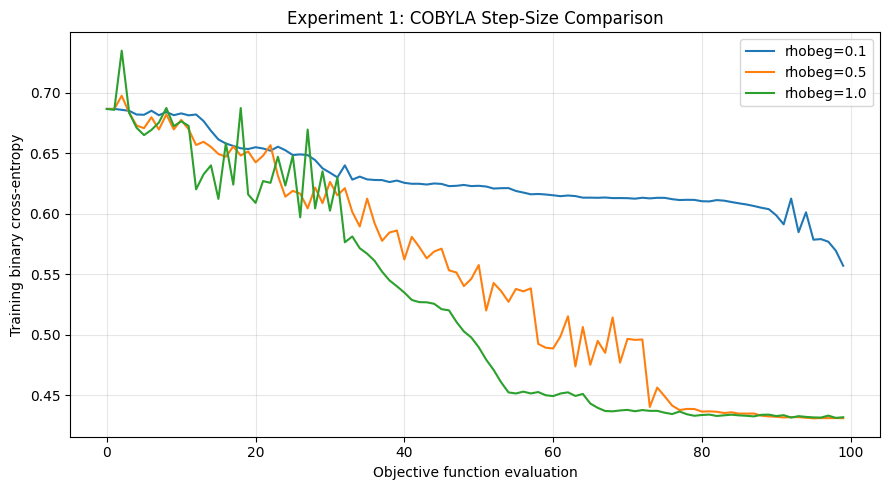

In [8]:
# ============================================================
# 3. EXPERIMENT 1: OPTIMIZER STEP-SIZE COMPARISON
# ============================================================

MAXITER = 100
RHOBEG_VALUES = [0.1, 0.5, 1.0]

optimizer_results = []
optimizer_models = {}
optimizer_losses = {}

for rhobeg in RHOBEG_VALUES:
    print(f"\nExperiment 1: rhobeg={rhobeg}")

    result, losses = train_vqc(
        X_train_angles,
        y_train,
        n_layers=2,
        rhobeg=rhobeg,
        maxiter=MAXITER,
        seed=SEED
    )

    val_preds = predict_classes(X_val_angles, result.x, n_layers=2)

    val_accuracy = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro", zero_division=0)

    optimizer_results.append({
        "Experiment": "Optimizer step size",
        "Layers": 2,
        "rhobeg": rhobeg,
        "Seed": SEED,
        "Training loss": result.fun,
        "Validation accuracy": val_accuracy,
        "Validation macro F1": val_f1,
        "Evaluations": result.nfev
    })

    optimizer_models[rhobeg] = result.x.copy()
    optimizer_losses[rhobeg] = losses

optimizer_df = pd.DataFrame(optimizer_results)
print("\nOptimizer experiment results:")
print(optimizer_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
for rhobeg, losses in optimizer_losses.items():
    plt.plot(losses, label=f"rhobeg={rhobeg}")

plt.xlabel("Objective function evaluation")
plt.ylabel("Training binary cross-entropy")
plt.title("Experiment 1: COBYLA Step-Size Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Best rhobeg from Experiment 1: 0.5

Experiment 2: circuit depth=1

Experiment 2: circuit depth=2

Experiment 2: circuit depth=3

Circuit depth results:
   Experiment  Layers  rhobeg  Seed  Training loss  Validation accuracy  Validation macro F1  Evaluations
Circuit depth       1     0.5    42         0.6319                  0.6               0.5833          100
Circuit depth       2     0.5    42         0.4309                  0.8               0.7847          100
Circuit depth       3     0.5    42         0.5506                  0.6               0.5982          100


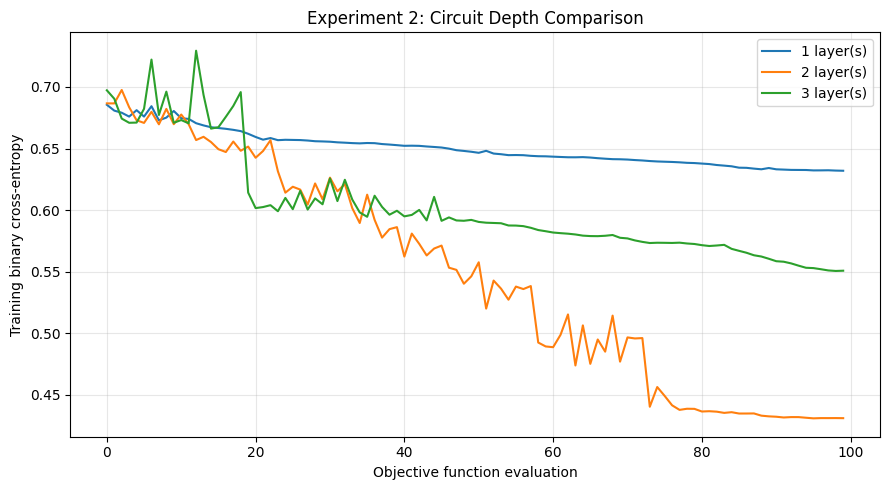

In [9]:
# ============================================================
# 4. EXPERIMENT 2: QUANTUM CIRCUIT DEPTH
# ============================================================

DEPTHS = [1, 2, 3]
depth_results = []
depth_models = {}
depth_losses = {}

# Use the best step size from Experiment 1
best_rhobeg = float(
    optimizer_df.sort_values(
        "Validation macro F1",
        ascending=False
    ).iloc[0]["rhobeg"]
)

print("\nBest rhobeg from Experiment 1:", best_rhobeg)

for depth in DEPTHS:
    print(f"\nExperiment 2: circuit depth={depth}")

    result, losses = train_vqc(
        X_train_angles,
        y_train,
        n_layers=depth,
        rhobeg=best_rhobeg,
        maxiter=MAXITER,
        seed=SEED
    )

    val_preds = predict_classes(X_val_angles, result.x, n_layers=depth)

    val_accuracy = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro", zero_division=0)

    depth_results.append({
        "Experiment": "Circuit depth",
        "Layers": depth,
        "rhobeg": best_rhobeg,
        "Seed": SEED,
        "Training loss": result.fun,
        "Validation accuracy": val_accuracy,
        "Validation macro F1": val_f1,
        "Evaluations": result.nfev
    })

    depth_models[depth] = result.x.copy()
    depth_losses[depth] = losses

depth_df = pd.DataFrame(depth_results)
print("\nCircuit depth results:")
print(depth_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
for depth, losses in depth_losses.items():
    plt.plot(losses, label=f"{depth} layer(s)")

plt.xlabel("Objective function evaluation")
plt.ylabel("Training binary cross-entropy")
plt.title("Experiment 2: Circuit Depth Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



Best depth from Experiment 2: 2

Experiment 3: initialization seed=7

Experiment 3: initialization seed=21

Experiment 3: initialization seed=42

Initialization results:
           Experiment  Layers  rhobeg  Seed  Training loss  Validation accuracy  Validation macro F1  Evaluations
Random initialization       2     0.5     7         0.5772               0.6667               0.6411          100
Random initialization       2     0.5    21         0.4323               0.8000               0.7847          100
Random initialization       2     0.5    42         0.4309               0.8000               0.7847          100


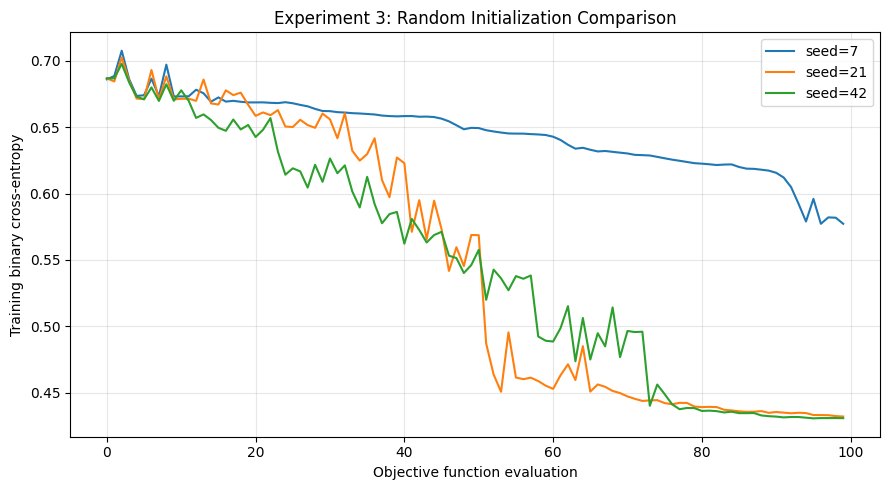

In [10]:
# ============================================================
# 5. EXPERIMENT 3: RANDOM INITIALIZATION
# ============================================================

INIT_SEEDS = [7, 21, 42]
initialization_results = []
initialization_models = {}
initialization_losses = {}

# Select depth using validation results from Experiment 2
best_depth_row = depth_df.sort_values(
    "Validation macro F1",
    ascending=False
).iloc[0]

best_depth = int(best_depth_row["Layers"])

print("\nBest depth from Experiment 2:", best_depth)

for init_seed in INIT_SEEDS:
    print(f"\nExperiment 3: initialization seed={init_seed}")

    result, losses = train_vqc(
        X_train_angles,
        y_train,
        n_layers=best_depth,
        rhobeg=best_rhobeg,
        maxiter=MAXITER,
        seed=init_seed
    )

    val_preds = predict_classes(
        X_val_angles,
        result.x,
        n_layers=best_depth
    )

    val_accuracy = accuracy_score(y_val, val_preds)
    val_f1 = f1_score(y_val, val_preds, average="macro", zero_division=0)

    initialization_results.append({
        "Experiment": "Random initialization",
        "Layers": best_depth,
        "rhobeg": best_rhobeg,
        "Seed": init_seed,
        "Training loss": result.fun,
        "Validation accuracy": val_accuracy,
        "Validation macro F1": val_f1,
        "Evaluations": result.nfev
    })

    initialization_models[init_seed] = result.x.copy()
    initialization_losses[init_seed] = losses

initialization_df = pd.DataFrame(initialization_results)
print("\nInitialization results:")
print(initialization_df.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))
for init_seed, losses in initialization_losses.items():
    plt.plot(losses, label=f"seed={init_seed}")

plt.xlabel("Objective function evaluation")
plt.ylabel("Training binary cross-entropy")
plt.title("Experiment 3: Random Initialization Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
# ============================================================
# 6. SELECT CONFIGURATION USING VALIDATION ONLY
# ============================================================

all_experiments = pd.concat(
    [optimizer_df, depth_df, initialization_df],
    ignore_index=True
)

# Each row represents one trained model; choose the best validation macro F1
best_config = all_experiments.sort_values(
    "Validation macro F1",
    ascending=False
).iloc[0]

selected_depth = int(best_config["Layers"])
selected_rhobeg = float(best_config["rhobeg"])
selected_seed = int(best_config["Seed"])

print("\nSelected configuration based on validation macro F1:")
print(f"Layers: {selected_depth}")
print(f"rhobeg: {selected_rhobeg}")
print(f"Initialization seed: {selected_seed}")
print(f"Validation macro F1: {best_config['Validation macro F1']:.4f}")


Selected configuration based on validation macro F1:
Layers: 2
rhobeg: 0.5
Initialization seed: 42
Validation macro F1: 0.7847


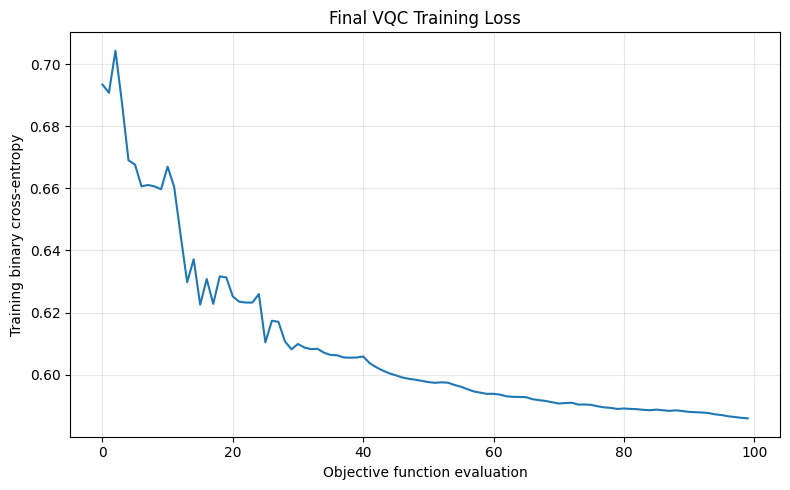


===== FINAL VQC TEST RESULTS =====
Accuracy: 0.7200
Macro F1: 0.7200
              precision    recall  f1-score   support

    High_BFE       0.75      0.69      0.72        13
     Low_BFE       0.69      0.75      0.72        12

    accuracy                           0.72        25
   macro avg       0.72      0.72      0.72        25
weighted avg       0.72      0.72      0.72        25



In [ ]:
# ============================================================
# 7. FINAL VQC TRAINING ON ALL OUTER TRAINING DATA
# ============================================================

final_vqc_result, final_loss_history = train_vqc(
    X_train_final_angles,
    y_train_full,
    n_layers=selected_depth,
    rhobeg=selected_rhobeg,
    maxiter=MAXITER,
    seed=selected_seed
)

final_weights = final_vqc_result.x

plt.figure(figsize=(8, 5))
plt.plot(final_loss_history)
plt.xlabel("Objective function evaluation")
plt.ylabel("Training binary cross-entropy")
plt.title("Final VQC Training Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Evaluate test set once, after all configuration choices
vqc_probs = predict_probabilities(
    X_test_final_angles,
    final_weights,
    selected_depth
)

vqc_preds = (vqc_probs >= 0.5).astype(int)

vqc_accuracy = accuracy_score(y_test, vqc_preds)
vqc_f1 = f1_score(y_test, vqc_preds, average="macro", zero_division=0)

print("\n===== FINAL VQC TEST RESULTS =====")
print(f"Accuracy: {vqc_accuracy:.4f}")
print(f"Macro F1: {vqc_f1:.4f}")
print(classification_report(
    y_test,
    vqc_preds,
    labels=[0, 1],
    target_names=[str(c) for c in unique_labels],
    zero_division=0
))


In [ ]:
# ============================================================
# 8. CLASSICAL RBF-SVM BASELINE
# ============================================================

svm_model = SVC(kernel="rbf", random_state=SEED)
svm_model.fit(X_train_final, y_train_full)
svm_preds = svm_model.predict(X_test_final)

svm_accuracy = accuracy_score(y_test, svm_preds)
svm_f1 = f1_score(y_test, svm_preds, average="macro", zero_division=0)

print("\n===== RBF-SVM TEST RESULTS =====")
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"Macro F1: {svm_f1:.4f}")
print(classification_report(
    y_test,
    svm_preds,
    labels=[0, 1],
    target_names=[str(c) for c in unique_labels],
    zero_division=0
))



===== RBF-SVM TEST RESULTS =====
Accuracy: 0.8400
Macro F1: 0.8377
              precision    recall  f1-score   support

    High_BFE       1.00      0.69      0.82        13
     Low_BFE       0.75      1.00      0.86        12

    accuracy                           0.84        25
   macro avg       0.88      0.85      0.84        25
weighted avg       0.88      0.84      0.84        25




===== FINAL COMPARISON =====
             Model  Accuracy  Macro F1
Custom Quantum VQC      0.72    0.7200
         SVM (RBF)      0.84    0.8377


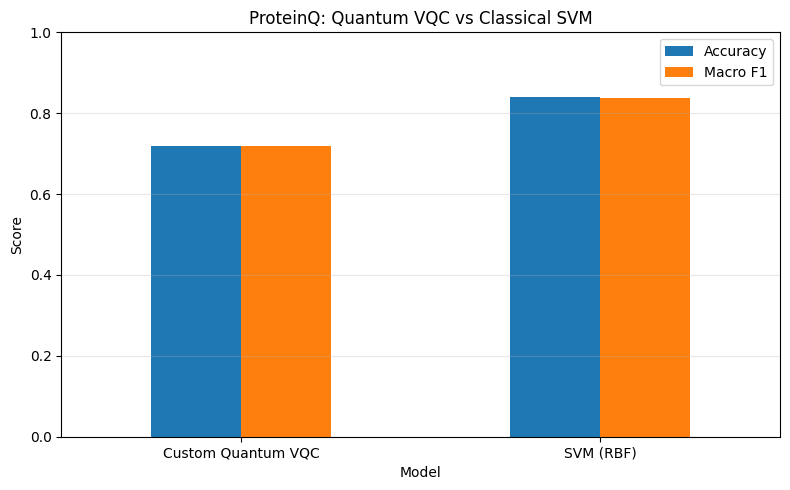

In [ ]:
# ============================================================
# 9. FINAL MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": ["Custom Quantum VQC", "SVM (RBF)"],
    "Accuracy": [vqc_accuracy, svm_accuracy],
    "Macro F1": [vqc_f1, svm_f1]
})

print("\n===== FINAL COMPARISON =====")
print(comparison.round(4).to_string(index=False))

comparison.set_index("Model").plot(
    kind="bar",
    ylim=(0, 1),
    figsize=(8, 5),
    rot=0
)

plt.ylabel("Score")
plt.title("ProteinQ: Quantum VQC vs Classical SVM")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

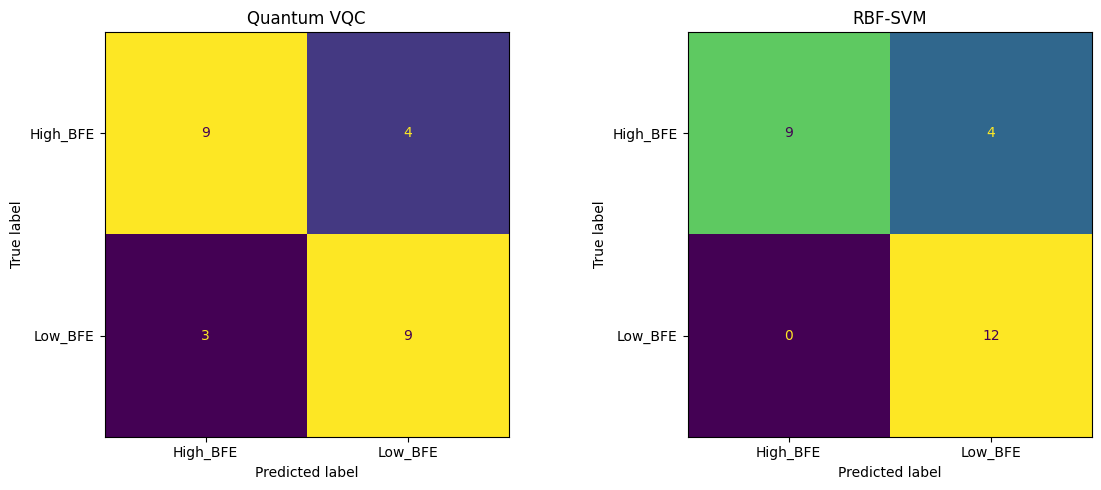

In [ ]:
# ============================================================
# 10. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, vqc_preds, labels=[0, 1]),
    display_labels=unique_labels
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Quantum VQC")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, svm_preds, labels=[0, 1]),
    display_labels=unique_labels
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("RBF-SVM")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("PROTEINQ EXPERIMENT SUMMARY")
print("=" * 55)
print(f"Dataset samples: {len(X_clean)}")
print(f"Input features: {N_QUBITS}")
print(f"Selected circuit depth: {selected_depth}")
print(f"Selected COBYLA rhobeg: {selected_rhobeg}")
print(f"Selected initialization seed: {selected_seed}")
print(f"VQC test accuracy: {vqc_accuracy:.4f}")
print(f"VQC test macro F1: {vqc_f1:.4f}")
print(f"SVM test accuracy: {svm_accuracy:.4f}")
print(f"SVM test macro F1: {svm_f1:.4f}")

print(
    "\nCaution: this is an exploratory small-data QML experiment. "
    "A comparison with SVM does not establish quantum advantage, "
    "and the labels are dataset classification targets rather than "
    "experimental confirmation of drug efficacy."
)



PROTEINQ EXPERIMENT SUMMARY
Dataset samples: 100
Input features: 6
Selected circuit depth: 2
Selected COBYLA rhobeg: 0.5
Selected initialization seed: 42
VQC test accuracy: 0.7200
VQC test macro F1: 0.7200
SVM test accuracy: 0.8400
SVM test macro F1: 0.8377

Caution: this is an exploratory small-data QML experiment. A comparison with SVM does not establish quantum advantage, and the labels are dataset classification targets rather than experimental confirmation of drug efficacy.


**Additional Experiments: VQC Stability, Classical Baselines, and Comparative Evaluation**

VQC Initialization Stability:


,Seed,Training Loss,Validation Accuracy,Validation Macro F1
0,1,0.4826,0.8667,0.8611
1,7,0.5772,0.6667,0.6411
2,13,0.6077,0.5333,0.5333
3,21,0.4323,0.8000,0.7847
4,29,0.4312,0.8000,0.7847
5,42,0.4309,0.8000,0.7847
6,55,0.4446,0.8000,0.7964
7,67,0.6149,0.3333,0.3304
8,81,0.4283,0.8000,0.7847
9,99,0.5196,0.7333,0.7222



Summary statistics:


,Validation Accuracy,Validation Macro F1
mean,0.7133,0.7023
std,0.1635,0.1606
min,0.3333,0.3304
max,0.8667,0.8611


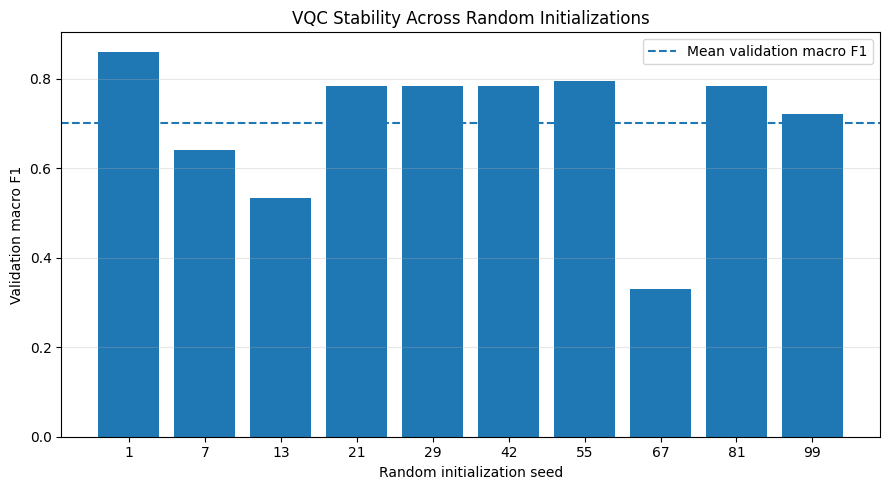

In [ ]:

# ============================================================
# EXPERIMENT 4: VQC STABILITY ACROSS 10 RANDOM INITIALIZATIONS
# ============================================================

stability_results = []

for seed in [1, 7, 13, 21, 29, 42, 55, 67, 81, 99]:
    result_seed, losses_seed = train_vqc(
        X_train_angles,
        y_train,
        n_layers=selected_depth,
        rhobeg=selected_rhobeg,
        maxiter=MAXITER,
        seed=seed
    )

    val_preds = predict_classes(
        X_val_angles,
        result_seed.x,
        selected_depth
    )

    stability_results.append({
        "Seed": seed,
        "Training Loss": result_seed.fun,
        "Validation Accuracy": accuracy_score(y_val, val_preds),
        "Validation Macro F1": f1_score(
            y_val, val_preds, average="macro", zero_division=0
        )
    })

stability_df = pd.DataFrame(stability_results)

print("VQC Initialization Stability:")
display(stability_df.round(4))

print("\nSummary statistics:")
display(
    stability_df[
        ["Validation Accuracy", "Validation Macro F1"]
    ].agg(["mean", "std", "min", "max"]).round(4)
)

plt.figure(figsize=(9, 5))
plt.bar(
    stability_df["Seed"].astype(str),
    stability_df["Validation Macro F1"]
)
plt.axhline(
    stability_df["Validation Macro F1"].mean(),
    linestyle="--",
    label="Mean validation macro F1"
)
plt.xlabel("Random initialization seed")
plt.ylabel("Validation macro F1")
plt.title("VQC Stability Across Random Initializations")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# EXPERIMENT 5: LOGISTIC REGRESSION BASELINE
# ============================================================

from sklearn.linear_model import LogisticRegression

logreg_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logreg_model.fit(X_train_scaled, y_train)
logreg_preds = logreg_model.predict(X_test_scaled)

logreg_accuracy = accuracy_score(y_test, logreg_preds)
logreg_macro_f1 = f1_score(
    y_test, logreg_preds, average="macro", zero_division=0
)

print("===== LOGISTIC REGRESSION RESULTS =====")
print(f"Accuracy: {logreg_accuracy:.4f}")
print(f"Macro F1: {logreg_macro_f1:.4f}")
print(classification_report(
    y_test,
    logreg_preds,
    labels=[0, 1],
    target_names=[str(c) for c in unique_labels],
    zero_division=0
))


===== LOGISTIC REGRESSION RESULTS =====
Accuracy: 0.8400
Macro F1: 0.8397
              precision    recall  f1-score   support

    High_BFE       0.91      0.77      0.83        13
     Low_BFE       0.79      0.92      0.85        12

    accuracy                           0.84        25
   macro avg       0.85      0.84      0.84        25
weighted avg       0.85      0.84      0.84        25



===== EXTENDED MODEL COMPARISON =====


,Model,Accuracy,Macro F1
0,Quantum VQC,0.72,0.7200
1,Logistic Regression,0.84,0.8397
2,RBF-SVM,0.84,0.8377


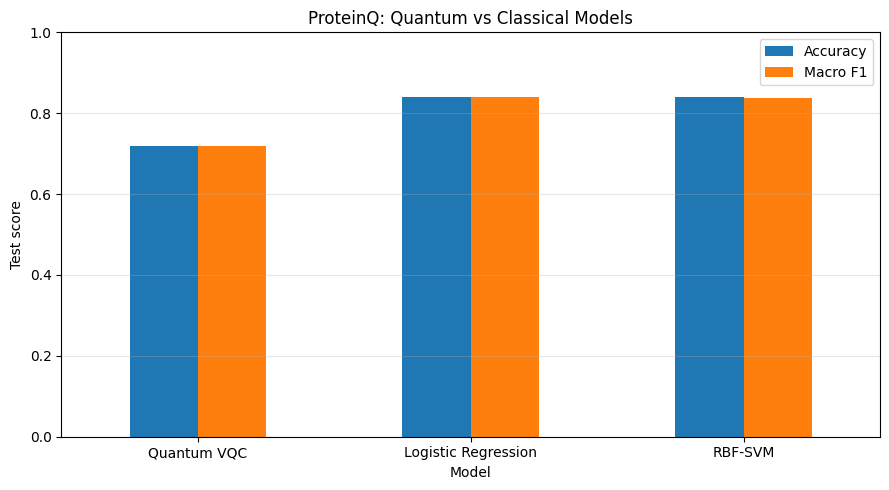

In [ ]:

# ============================================================
# EXPERIMENT 6: THREE-MODEL COMPARISON
# ============================================================

comparison_extended = pd.DataFrame({
    "Model": [
        "Quantum VQC",
        "Logistic Regression",
        "RBF-SVM"
    ],
    "Accuracy": [
        vqc_accuracy,
        logreg_accuracy,
        svm_accuracy
    ],
    "Macro F1": [
        vqc_f1,
        logreg_macro_f1,
        svm_f1
    ]
})

print("===== EXTENDED MODEL COMPARISON =====")
display(comparison_extended.round(4))

comparison_extended.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.ylabel("Test score")
plt.title("ProteinQ: Quantum vs Classical Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


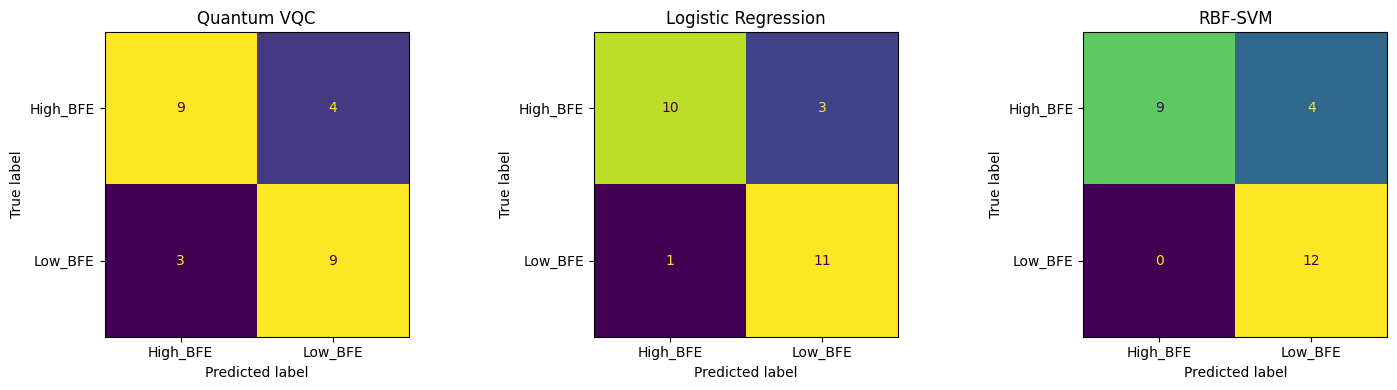

In [ ]:

# ============================================================
# EXPERIMENT 7: CONFUSION MATRIX COMPARISON
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

model_predictions = [
    ("Quantum VQC", vqc_preds),
    ("Logistic Regression", logreg_preds),
    ("RBF-SVM", svm_preds)
]

for ax, (name, predictions) in zip(axes, model_predictions):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=unique_labels,
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# EXPERIMENT 8: SAVE RESULTS FOR THE WRITE-UP
# ============================================================

stability_df.to_csv(
    "proteinQ_initialization_stability.csv",
    index=False
)

comparison_extended.to_csv(
    "proteinQ_three_model_comparison.csv",
    index=False
)

print("Exported experiment results:")
print("- proteinQ_initialization_stability.csv")
print("- proteinQ_three_model_comparison.csv")


Exported experiment results:
- proteinQ_initialization_stability.csv
- proteinQ_three_model_comparison.csv


EXTENDED MODEL COMPARISON — RESULTS
Quantum VQC            Accuracy: 0.7200 | Macro F1: 0.7200
Logistic Regression    Accuracy: 0.8400 | Macro F1: 0.8397
RBF-SVM                Accuracy: 0.8400 | Macro F1: 0.8377

INTERPRETATION
Best model by Macro F1: Logistic Regression (0.8397)
Accuracy gap between best model and VQC: 0.1200

Conclusion: Classical baselines performed better than the VQC on this test split. These results do not demonstrate quantum advantage.


,Model,Accuracy,Macro F1
0,Quantum VQC,0.72,0.7200
1,Logistic Regression,0.84,0.8397
2,RBF-SVM,0.84,0.8377


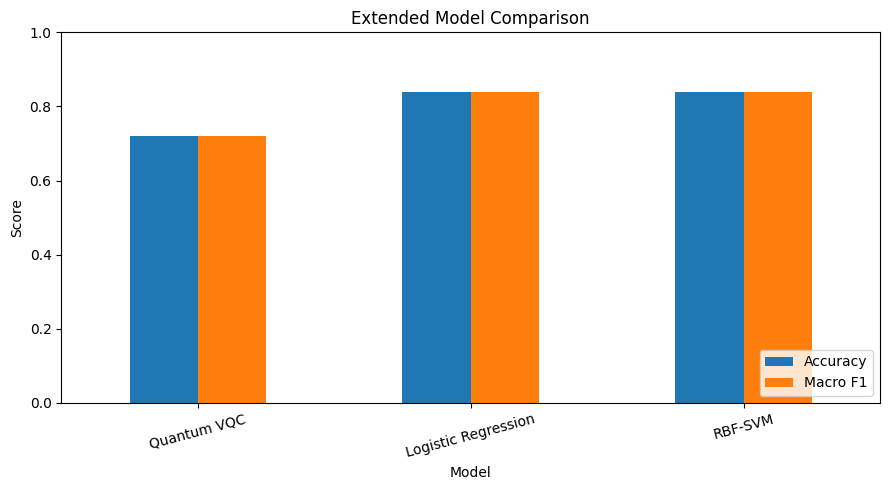

In [ ]:
# Extended Model Comparison: Results and Interpretation

print("=" * 55)
print("EXTENDED MODEL COMPARISON — RESULTS")
print("=" * 55)

for _, row in comparison_extended.iterrows():
    print(
        f"{row['Model']:<22} "
        f"Accuracy: {row['Accuracy']:.4f} | "
        f"Macro F1: {row['Macro F1']:.4f}"
    )

best_model = comparison_extended.loc[
    comparison_extended["Macro F1"].idxmax()
]

print("\nINTERPRETATION")
print(
    f"Best model by Macro F1: {best_model['Model']} "
    f"({best_model['Macro F1']:.4f})"
)

vqc_accuracy_value = comparison_extended.loc[
    comparison_extended["Model"] == "Quantum VQC", "Accuracy"
].iloc[0]

accuracy_gap = best_model["Accuracy"] - vqc_accuracy_value

print(f"Accuracy gap between best model and VQC: {accuracy_gap:.4f}")
print(
    "\nConclusion: Classical baselines performed better than the VQC "
    "on this test split. These results do not demonstrate quantum advantage."
)

display(comparison_extended.round(4))

comparison_extended.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=15
)

plt.title("Extended Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Feature Reduction Analysis - EXPERIMENT 9: QML vs CLASSICAL ML WITH FEATURE REDUCTION**


=== 6 features: ['SP-6', 'FMF', 'minHaaCH', 'SC-5', 'maxwHBa', 'SHBd'] ===
  VQC seed 7: acc=0.760, macro F1=0.760
  VQC seed 21: acc=0.760, macro F1=0.760
  VQC seed 42: acc=0.760, macro F1=0.760
  VQC seed 13: acc=0.800, macro F1=0.800
  VQC seed 99: acc=0.760, macro F1=0.760

=== 4 features: ['SP-6', 'FMF', 'minHaaCH', 'SC-5'] ===
  VQC seed 7: acc=0.760, macro F1=0.760
  VQC seed 21: acc=0.760, macro F1=0.760
  VQC seed 42: acc=0.760, macro F1=0.760
  VQC seed 13: acc=0.760, macro F1=0.760
  VQC seed 99: acc=0.760, macro F1=0.760

=== 2 features: ['SP-6', 'FMF'] ===
  VQC seed 7: acc=0.880, macro F1=0.880
  VQC seed 21: acc=0.880, macro F1=0.880
  VQC seed 42: acc=0.880, macro F1=0.880
  VQC seed 13: acc=0.880, macro F1=0.880
  VQC seed 99: acc=0.880, macro F1=0.880

===== QML vs CLASSICAL ML WITH FEATURE REDUCTION (test set) =====
 Features               Model Accuracy (mean ± std) Macro F1 (mean ± std)
        6 Logistic Regression                 0.800                 0.799
   

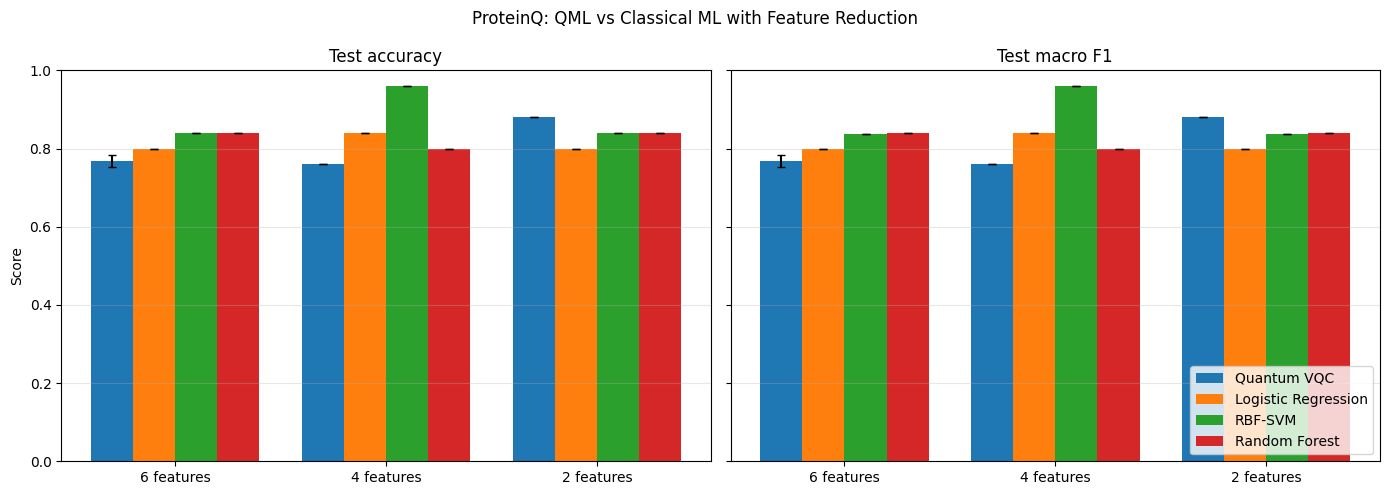

In [ ]:
# ============================================================
# EXPERIMENT 9: QML vs CLASSICAL ML WITH FEATURE REDUCTION
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Random Forest importances, fit on the training split
ranked_features = ['SP-6', 'FMF', 'minHaaCH', 'SC-5', 'maxwHBa', 'SHBd']
K_VALUES = [6, 4, 2]
VQC_SEEDS = [7, 21, 42, 13, 99]      # reduce to 3 seeds if runtime is too long

all_cols = X_clean.columns.tolist()
missing = [f for f in ranked_features if f not in all_cols]
assert not missing, f"Features not found in dataset: {missing}"

ORIG_N_QUBITS = N_QUBITS             # train_vqc reads N_QUBITS as a global
rows = []

try:
    for k in K_VALUES:
        feats = ranked_features[:k]
        idx = [all_cols.index(f) for f in feats]
        print(f"\n=== {k} features: {feats} ===")

        # Column-subset the already-scaled / angle-encoded arrays
        Xtr = X_train_final[:, idx]
        Xte = X_test_final[:, idx]
        Xtr_ang = X_train_final_angles[:, idx]
        Xte_ang = X_test_final_angles[:, idx]

        # ---------- Classical models ----------
        classical_models = {
            "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
            "RBF-SVM": SVC(kernel="rbf", random_state=SEED),
            "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
        }
        for name, model in classical_models.items():
            model.fit(Xtr, y_train_full)
            preds = model.predict(Xte)
            rows.append({
                "Model": name,
                "Features": k,
                "Accuracy": accuracy_score(y_test, preds),
                "Accuracy std": 0.0,
                "Macro F1": f1_score(y_test, preds, average="macro", zero_division=0),
                "Macro F1 std": 0.0,
            })

        # ---------- Quantum VQC (multiple seeds) ----------
        N_QUBITS = k
        accs, f1s, single_class_runs = [], [], 0
        for s in VQC_SEEDS:
            result, _ = train_vqc(
                Xtr_ang, y_train_full,
                n_layers=selected_depth,
                rhobeg=selected_rhobeg,
                maxiter=MAXITER,
                seed=s
            )
            preds = predict_classes(Xte_ang, result.x, selected_depth)
            accs.append(accuracy_score(y_test, preds))
            f1s.append(f1_score(y_test, preds, average="macro", zero_division=0))
            if len(np.unique(preds)) == 1:
                single_class_runs += 1
            print(f"  VQC seed {s}: acc={accs[-1]:.3f}, macro F1={f1s[-1]:.3f}")

        if single_class_runs:
            print(f"  WARNING: {single_class_runs}/{len(VQC_SEEDS)} VQC runs predicted a single class")

        rows.append({
            "Model": "Quantum VQC",
            "Features": k,
            "Accuracy": np.mean(accs),
            "Accuracy std": np.std(accs),
            "Macro F1": np.mean(f1s),
            "Macro F1 std": np.std(f1s),
        })
finally:
    N_QUBITS = ORIG_N_QUBITS         # always restore the global

# ---------- Results table ----------
fr_df = pd.DataFrame(rows)
fr_df["Accuracy (mean ± std)"] = fr_df.apply(
    lambda r: f"{r['Accuracy']:.3f} ± {r['Accuracy std']:.3f}" if r["Model"] == "Quantum VQC"
    else f"{r['Accuracy']:.3f}", axis=1)
fr_df["Macro F1 (mean ± std)"] = fr_df.apply(
    lambda r: f"{r['Macro F1']:.3f} ± {r['Macro F1 std']:.3f}" if r["Model"] == "Quantum VQC"
    else f"{r['Macro F1']:.3f}", axis=1)

print("\n===== QML vs CLASSICAL ML WITH FEATURE REDUCTION (test set) =====")
print(fr_df[["Features", "Model", "Accuracy (mean ± std)", "Macro F1 (mean ± std)"]]
      .sort_values(["Features", "Model"], ascending=[False, True])
      .to_string(index=False))

fr_df.drop(columns=["Accuracy (mean ± std)", "Macro F1 (mean ± std)"]).to_csv(
    "proteinQ_feature_reduction_comparison.csv", index=False)

# ---------- Plot ----------
models = ["Quantum VQC", "Logistic Regression", "RBF-SVM", "Random Forest"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
width = 0.2
x = np.arange(len(K_VALUES))

for ax, (metric, title) in zip(axes, [("Accuracy", "Test accuracy"), ("Macro F1", "Test macro F1")]):
    for i, m in enumerate(models):
        sub = fr_df[fr_df["Model"] == m].set_index("Features").loc[K_VALUES]
        ax.bar(x + (i - 1.5) * width, sub[metric], width,
               yerr=sub[f"{metric} std"], capsize=3, label=m)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{k} features" for k in K_VALUES])
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Score")
axes[1].legend(loc="lower right")
plt.suptitle("ProteinQ: QML vs Classical ML with Feature Reduction")
plt.tight_layout()
plt.show()

k=6: train acc=0.813, test acc=0.760
k=4: train acc=0.813, test acc=0.760
k=2: train acc=0.840, test acc=0.880


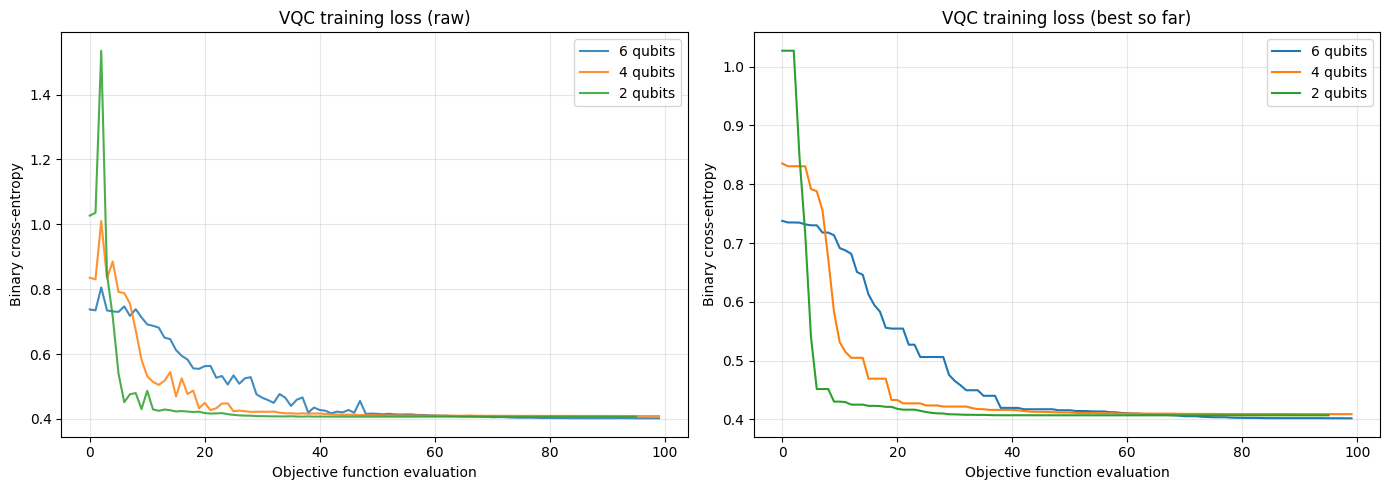

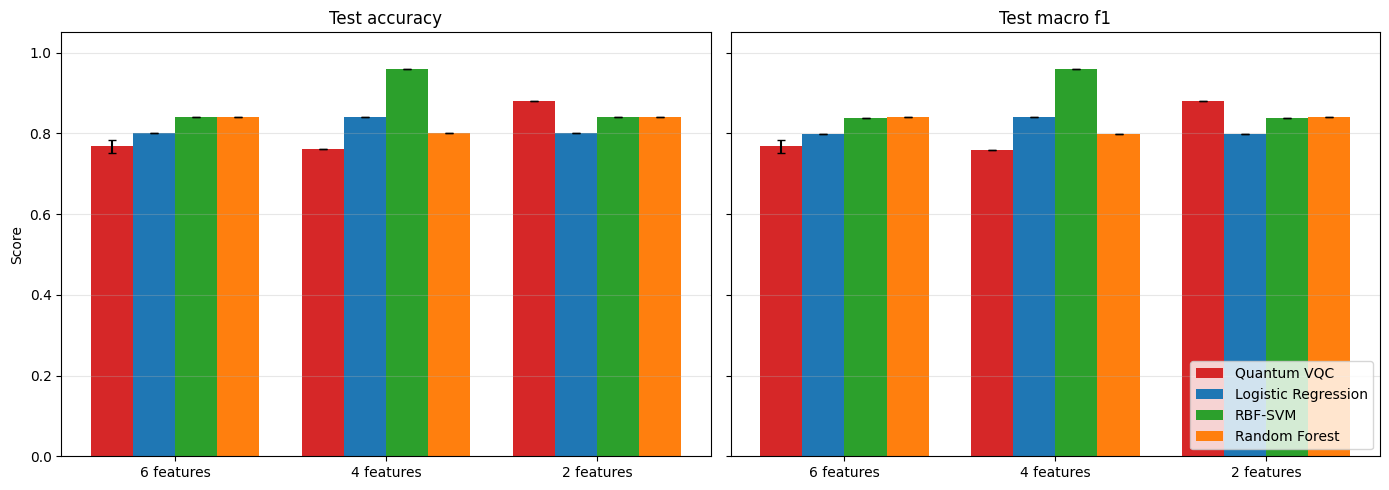

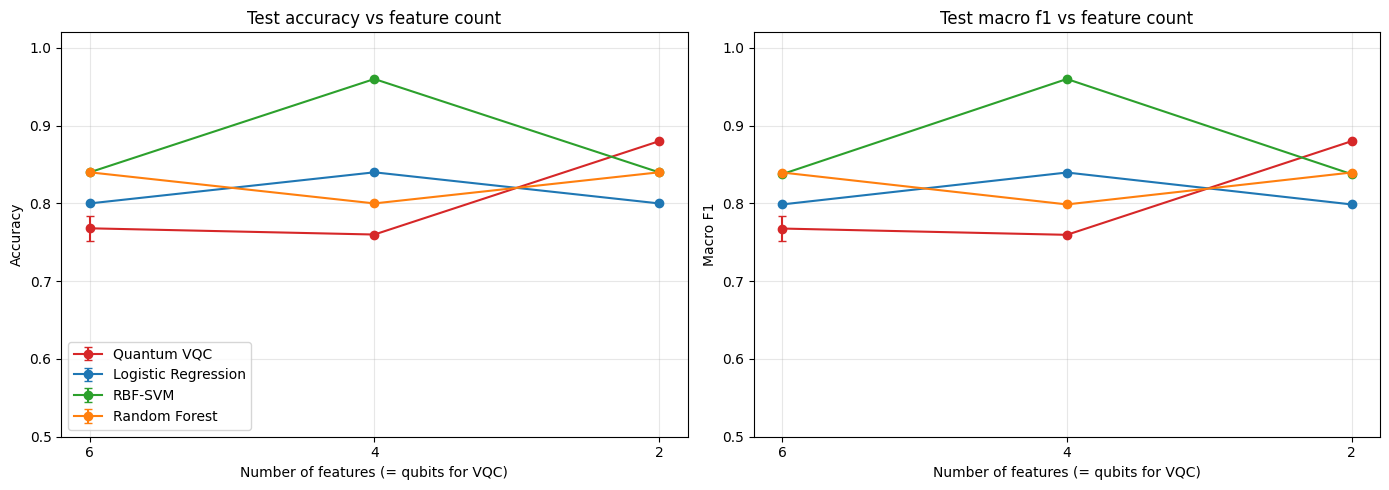

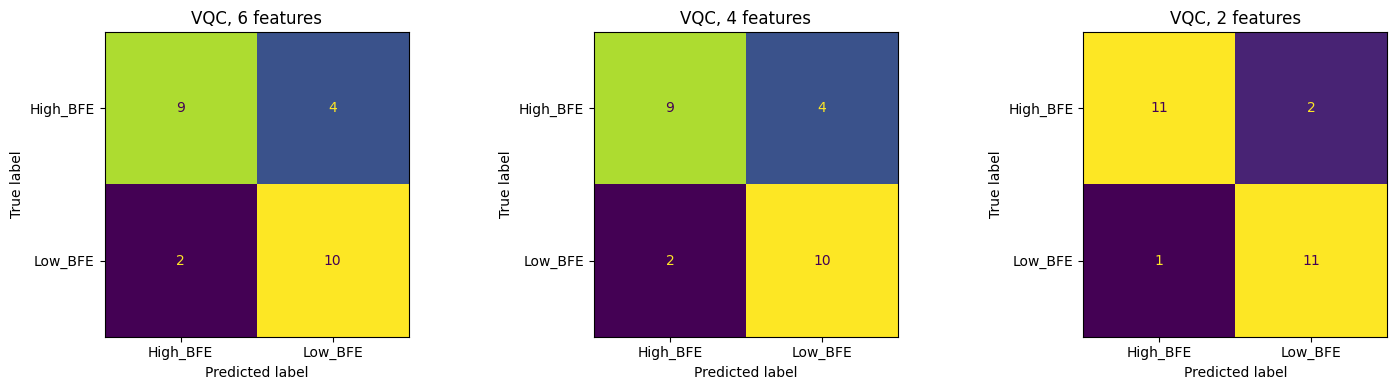

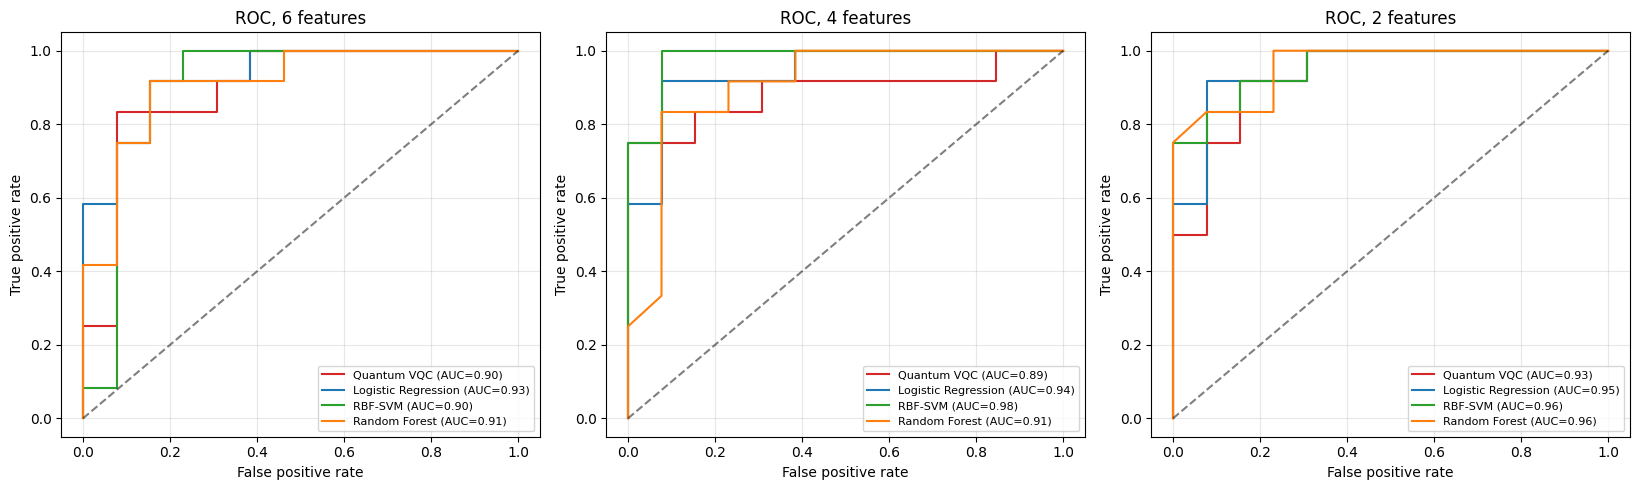

In [13]:
# ============================================================
# EXPERIMENT 10: PLOTS FOR FEATURE-REDUCTION COMPARISON
# ============================================================
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

ranked_features = ['SP-6', 'FMF', 'minHaaCH', 'SC-5', 'maxwHBa', 'SHBd']
all_cols = X_clean.columns.tolist()
K_VALUES = [6, 4, 2]
models_order = ["Quantum VQC", "Logistic Regression", "RBF-SVM", "Random Forest"]
colors = dict(zip(models_order, ["tab:red", "tab:blue", "tab:green", "tab:orange"]))

# ---------- 1. Retrain one VQC per k (keeps loss history + probabilities) ----------
ORIG_N_QUBITS = N_QUBITS
vqc_runs = {}
try:
    for k in K_VALUES:
        idx = [all_cols.index(f) for f in ranked_features[:k]]
        N_QUBITS = k
        res, losses = train_vqc(
            X_train_final_angles[:, idx], y_train_full,
            n_layers=selected_depth, rhobeg=selected_rhobeg,
            maxiter=MAXITER, seed=selected_seed
        )
        test_probs = predict_probabilities(X_test_final_angles[:, idx], res.x, selected_depth)
        train_probs = predict_probabilities(X_train_final_angles[:, idx], res.x, selected_depth)
        vqc_runs[k] = {
            "idx": idx, "losses": losses,
            "test_probs": test_probs, "test_preds": (test_probs >= 0.5).astype(int),
            "train_acc": accuracy_score(y_train_full, (train_probs >= 0.5).astype(int)),
        }
        print(f"k={k}: train acc={vqc_runs[k]['train_acc']:.3f}, "
              f"test acc={accuracy_score(y_test, vqc_runs[k]['test_preds']):.3f}")
finally:
    N_QUBITS = ORIG_N_QUBITS

# ---------- 2. VQC training curves ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for k in K_VALUES:
    losses = np.array(vqc_runs[k]["losses"])
    axes[0].plot(losses, label=f"{k} qubits", alpha=0.85)
    axes[1].plot(np.minimum.accumulate(losses), label=f"{k} qubits")
axes[0].set_title("VQC training loss (raw)")
axes[1].set_title("VQC training loss (best so far)")
for ax in axes:
    ax.set_xlabel("Objective function evaluation")
    ax.set_ylabel("Binary cross-entropy")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
fig.savefig("fr_training_curves.png", dpi=200)
plt.show()

# ---------- 3. Accuracy and macro F1 bar charts (from fr_df) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
width, x = 0.2, np.arange(len(K_VALUES))
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    for i, m in enumerate(models_order):
        sub = fr_df[fr_df["Model"] == m].set_index("Features").loc[K_VALUES]
        ax.bar(x + (i - 1.5) * width, sub[metric], width,
               yerr=sub[f"{metric} std"], capsize=3, label=m, color=colors[m])
    ax.set_xticks(x)
    ax.set_xticklabels([f"{k} features" for k in K_VALUES])
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Test {metric.lower()}")
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Score")
axes[1].legend(loc="lower right")
plt.tight_layout()
fig.savefig("fr_bar_comparison.png", dpi=200)
plt.show()

# ---------- 4. Accuracy vs number of features ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    for m in models_order:
        sub = fr_df[fr_df["Model"] == m].set_index("Features").loc[K_VALUES]
        ax.errorbar(K_VALUES, sub[metric], yerr=sub[f"{metric} std"],
                    marker="o", capsize=3, label=m, color=colors[m])
    ax.set_xticks(K_VALUES)
    ax.invert_xaxis()
    ax.set_xlabel("Number of features (= qubits for VQC)")
    ax.set_ylabel(metric)
    ax.set_ylim(0.5, 1.02)
    ax.set_title(f"Test {metric.lower()} vs feature count")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
fig.savefig("fr_metric_vs_features.png", dpi=200)
plt.show()

# ---------- 5. VQC confusion matrices ----------
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(5 * len(K_VALUES), 4))
for ax, k in zip(axes, K_VALUES):
    ConfusionMatrixDisplay.from_predictions(
        y_test, vqc_runs[k]["test_preds"], labels=[0, 1],
        display_labels=unique_labels, ax=ax, colorbar=False
    )
    ax.set_title(f"VQC, {k} features")
plt.tight_layout()
fig.savefig("fr_vqc_confusion.png", dpi=200)
plt.show()

# ---------- 6. ROC curves per feature count ----------
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(5.5 * len(K_VALUES), 5))
for ax, k in zip(axes, K_VALUES):
    idx = vqc_runs[k]["idx"]
    Xtr, Xte = X_train_final[:, idx], X_test_final[:, idx]

    lr = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xtr, y_train_full)
    svm = SVC(kernel="rbf", random_state=SEED).fit(Xtr, y_train_full)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(Xtr, y_train_full)

    scores = {
        "Quantum VQC": vqc_runs[k]["test_probs"],
        "Logistic Regression": lr.predict_proba(Xte)[:, 1],
        "RBF-SVM": svm.decision_function(Xte),
        "Random Forest": rf.predict_proba(Xte)[:, 1],
    }
    for m in models_order:
        fpr, tpr, _ = roc_curve(y_test, scores[m])
        ax.plot(fpr, tpr, color=colors[m], label=f"{m} (AUC={auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(f"ROC, {k} features")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("fr_roc_curves.png", dpi=200)
plt.show()

In [14]:
for k in [6, 4, 2]:
    idx = vqc_runs[k]["idx"]
    svm = SVC(kernel="rbf", random_state=SEED).fit(X_train_final[:, idx], y_train_full)
    print(k, "SVM train acc:", round(svm.score(X_train_final[:, idx], y_train_full), 3))

6 SVM train acc: 0.853
4 SVM train acc: 0.827
2 SVM train acc: 0.813


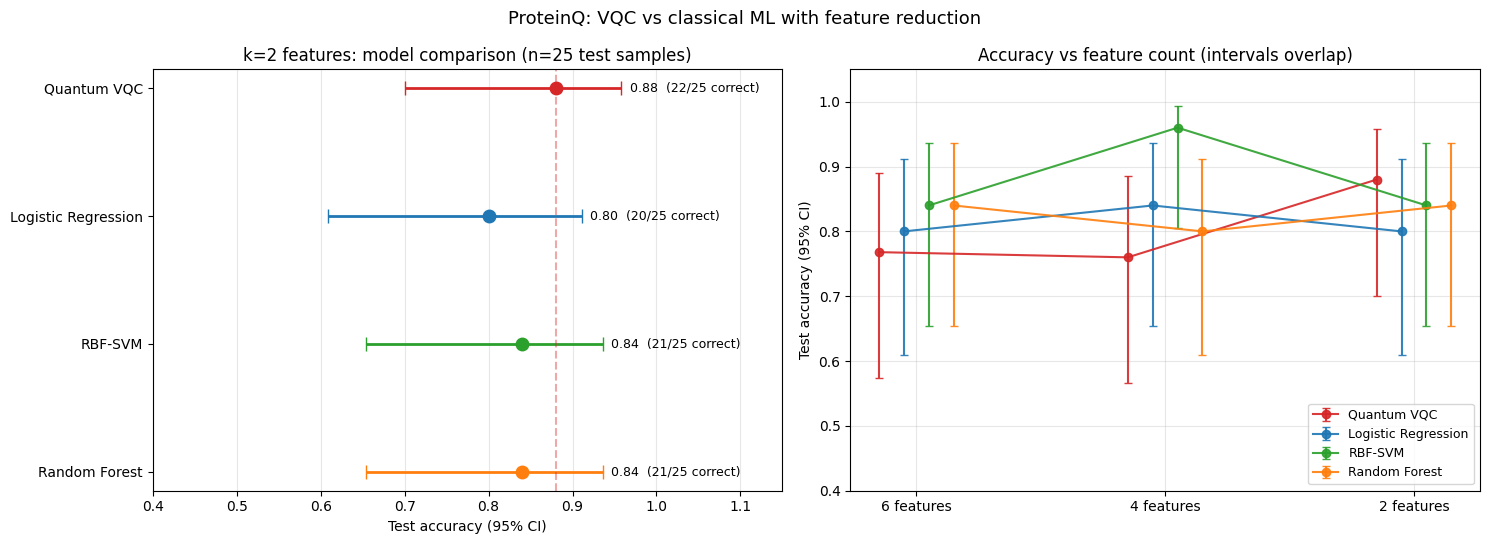


k=2 test accuracy with 95% Wilson CI (n=25):
  Quantum VQC            0.880  [0.700, 0.958]
  Logistic Regression    0.800  [0.609, 0.911]
  RBF-SVM                0.840  [0.653, 0.936]
  Random Forest          0.840  [0.653, 0.936]


In [16]:
# ============================================================
# EXPERIMENT 11: IS VQC REALLY BETTER AT k=2? (WITH UNCERTAINTY)
# ============================================================

n_test = len(y_test)

def wilson_ci(acc, n, z=1.96):
    """95% Wilson confidence interval for an accuracy measured on n samples."""
    center = (acc + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(acc * (1 - acc) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half

models_order = ["Quantum VQC", "Logistic Regression", "RBF-SVM", "Random Forest"]
colors = dict(zip(models_order, ["tab:red", "tab:blue", "tab:green", "tab:orange"]))
K_VALUES = [6, 4, 2]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# ---------- Panel 1: all models at k=2 with 95% CI ----------
ax = axes[0]
sub = fr_df[fr_df["Features"] == 2].set_index("Model").loc[models_order]
for i, m in enumerate(models_order):
    acc = sub.loc[m, "Accuracy"]
    lo, hi = wilson_ci(acc, n_test)
    ax.errorbar(acc, i, xerr=[[acc - lo], [hi - acc]], fmt="o", color=colors[m],
                capsize=5, markersize=9, linewidth=2)
    ax.text(hi + 0.01, i, f"{acc:.2f}  ({round(acc * n_test)}/{n_test} correct)",
            va="center", fontsize=9)

ax.axvline(sub.loc["Quantum VQC", "Accuracy"], color="tab:red", linestyle="--", alpha=0.4)
ax.set_yticks(range(len(models_order)))
ax.set_yticklabels(models_order)
ax.invert_yaxis()
ax.set_xlim(0.4, 1.15)
ax.set_xlabel("Test accuracy (95% CI)")
ax.set_title(f"k=2 features: model comparison (n={n_test} test samples)")
ax.grid(axis="x", alpha=0.3)

# ---------- Panel 2: all models across k with 95% CI ----------
ax = axes[1]
offsets = np.linspace(-0.15, 0.15, len(models_order))
for off, m in zip(offsets, models_order):
    s = fr_df[fr_df["Model"] == m].set_index("Features").loc[K_VALUES]
    accs = s["Accuracy"].values
    cis = np.array([wilson_ci(a, n_test) for a in accs])
    xpos = np.arange(len(K_VALUES)) + off
    ax.errorbar(xpos, accs, yerr=[accs - cis[:, 0], cis[:, 1] - accs],
                fmt="o-", color=colors[m], capsize=3, label=m, alpha=0.9)

ax.set_xticks(range(len(K_VALUES)))
ax.set_xticklabels([f"{k} features" for k in K_VALUES])
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("Test accuracy (95% CI)")
ax.set_title("Accuracy vs feature count (intervals overlap)")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.3)

plt.suptitle("ProteinQ: VQC vs classical ML with feature reduction", fontsize=13)
plt.tight_layout()
fig.savefig("fr_k2_with_uncertainty.png", dpi=200)
plt.show()

# ---------- Text summary at k=2 ----------
print(f"\nk=2 test accuracy with 95% Wilson CI (n={n_test}):")
for m in models_order:
    acc = sub.loc[m, "Accuracy"]
    lo, hi = wilson_ci(acc, n_test)
    print(f"  {m:<22} {acc:.3f}  [{lo:.3f}, {hi:.3f}]")

## Feature Reduction: QML vs Classical ML (Summary Notes)

**Setup**
- Features were ranked by Random Forest importance, fit on the training split only: SP-6 > FMF > minHaaCH > SC-5 > maxwHBa > SHBd.
- Models were compared on the top 6, top 4, and top 2 features. For the VQC, the number of features equals the number of qubits.
- Models: custom VQC (RY angle encoding, RY layers with a CNOT chain, 1 measured qubit, COBYLA, 100 iterations), Logistic Regression, RBF-SVM, Random Forest.
- The VQC used the depth and `rhobeg` selected on the validation split with all 6 features (not re-tuned per feature count) and was trained with 5 random initializations.
- All models used the same split (75 train / 25 test, stratified, seed 42).

**Test results (accuracy)**

| Features | VQC | Logistic Regression | RBF-SVM | Random Forest |
|---|---|---|---|---|
| 6 | 0.768 ± 0.016 | 0.800 | 0.840 | 0.840 |
| 4 | 0.760 ± 0.000 | 0.840 | 0.960 | 0.800 |
| 2 | 0.880 ± 0.000 | 0.800 | 0.840 | 0.840 |

**Train accuracy (single run)**
- VQC: 0.813 (6), 0.813 (4), 0.840 (2)
- RBF-SVM: 0.853 (6), 0.827 (4), 0.813 (2)

**Observations**
- The VQC scored highest at 2 features (0.88), compared with 0.76 at 4 and 6 features. At 6 and 4 features it trails the classical models.
- Neither the VQC nor the SVM overfits: train and test accuracy are close, and both fit the training data at about 0.81 to 0.85.
- At 2 features the VQC (0.88) is on par with the classical models (0.80 to 0.84). The 95% confidence intervals (Wilson, n=25) overlap: VQC [0.70, 0.96] vs classical [0.61, 0.94].
- The SVM's 0.96 at 4 features is likely a favorable test split (its train accuracy there is 0.827), not a real jump in performance.
- The 0.000 seed std for the VQC reflects the same circuit converging to the same solution each time. It does not measure uncertainty about the test set.

**Conclusion**
In conclusion, quantum feature reduction (k=2) achieved comparable classification performance with fewer features, suggesting its potential for efficient molecular analysis.
